# Determinação gráfica da resistência elétrica

A resistência elétrica será determinada pelo coeficiente angular da
reta obtida no gráfico da tensão média em função da corrente média.

As leituras experimentais serão preservadas. O fator de escala do
miliamperímetro será determinado a partir da faixa utilizada no
instrumento, sem empregar o valor nominal ou a medição direta do
resistor para corrigir os dados.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [6]:
df_medias = pd.DataFrame({
    "posicao": [2, 4, 6, 8, 10],

    "tensao_media_V": [
        4.80,
        10.35,
        15.95,
        21.05,
        26.15
    ],

    "desvio_tensao_V": [
        0.36,
        0.39,
        0.74,
        0.33,
        0.24
    ],

    "leitura_media_corrente": [
        3.45,
        4.025,
        4.675,
        5.275,
        5.60
    ],

    "desvio_corrente": [
        0.54,
        0.46,
        0.46,
        0.25,
        0.40
    ]
})

df_medias

,posicao,tensao_media_V,desvio_tensao_V,leitura_media_corrente,desvio_corrente
0,2,4.80,0.36,3.450,0.54
1,4,10.35,0.39,4.025,0.46
2,6,15.95,0.74,4.675,0.46
3,8,21.05,0.33,5.275,0.25
4,10,26.15,0.24,5.600,0.40


## Fator de escala do miliamperímetro

O mostrador do miliamperímetro apresenta uma escala de 0 a 75.
Considerando a utilização da faixa de 75 mA, o fator de escala é:

$$
f_{\mathrm{escala}}
=
\frac{75\ \mathrm{mA}}{75}
=
1\ \mathrm{mA/divisão}.
$$

Portanto, cada unidade indicada na escala corresponde a 1 mA.

In [7]:
valor_maximo_escala = 75
faixa_utilizada_mA = 75

fator_escala = faixa_utilizada_mA / valor_maximo_escala

print(f"Fator de escala = {fator_escala:.2f} mA por divisão")

Fator de escala = 1.00 mA por divisão


In [8]:
df_medias["corrente_media_mA"] = (
    df_medias["leitura_media_corrente"] * fator_escala
)

df_medias

,posicao,tensao_media_V,desvio_tensao_V,leitura_media_corrente,desvio_corrente,corrente_media_mA
0,2,4.80,0.36,3.450,0.54,3.450
1,4,10.35,0.39,4.025,0.46,4.025
2,6,15.95,0.74,4.675,0.46,4.675
3,8,21.05,0.33,5.275,0.25,5.275
4,10,26.15,0.24,5.600,0.40,5.600


In [9]:
df_medias["corrente_media_A"] = (
    df_medias["corrente_media_mA"] / 1000
)

df_medias

,posicao,tensao_media_V,desvio_tensao_V,leitura_media_corrente,desvio_corrente,corrente_media_mA,corrente_media_A
0,2,4.80,0.36,3.450,0.54,3.450,0.003450
1,4,10.35,0.39,4.025,0.46,4.025,0.004025
2,6,15.95,0.74,4.675,0.46,4.675,0.004675
3,8,21.05,0.33,5.275,0.25,5.275,0.005275
4,10,26.15,0.24,5.600,0.40,5.600,0.005600


In [10]:
x = df_medias["corrente_media_A"].to_numpy()
y = df_medias["tensao_media_V"].to_numpy()

R_grafico, intercepto = np.polyfit(x, y, 1)

y_estimado = R_grafico * x + intercepto

ss_res = np.sum((y - y_estimado) ** 2)
ss_tot = np.sum((y - y.mean()) ** 2)

r2 = 1 - ss_res / ss_tot

print(f"Resistência pelo gráfico = {R_grafico:.2f} Ω")
print(f"Intercepto = {intercepto:.2f} V")
print(f"R² = {r2:.4f}")

Resistência pelo gráfico = 9534.32 Ω
Intercepto = -28.25 V
R² = 0.9922


In [12]:
R_direta = 390
tolerancia = 0.05

R_min = R_direta * (1 - tolerancia)
R_max = R_direta * (1 + tolerancia)

diferenca_absoluta = abs(R_grafico - R_direta)

diferenca_percentual = (
    diferenca_absoluta / R_direta
) * 100

print(f"Resistência pelo gráfico = {R_grafico:.2f} Ω")
print(f"Resistência direta = {R_direta:.2f} Ω")
print(f"Intervalo de 5% = {R_min:.2f} a {R_max:.2f} Ω")
print(f"Diferença absoluta = {diferenca_absoluta:.2f} Ω")
print(f"Diferença percentual = {diferenca_percentual:.2f}%")

Resistência pelo gráfico = 9534.32 Ω
Resistência direta = 390.00 Ω
Intervalo de 5% = 370.50 a 409.50 Ω
Diferença absoluta = 9144.32 Ω
Diferença percentual = 2344.70%


In [13]:
df_diagnostico = df_medias[[
    "posicao",
    "tensao_media_V",
    "corrente_media_mA"
]].copy()

df_diagnostico["corrente_esperada_mA"] = (
    df_diagnostico["tensao_media_V"] / R_direta
) * 1000

df_diagnostico["fator_aparente"] = (
    df_diagnostico["corrente_esperada_mA"]
    / df_diagnostico["corrente_media_mA"]
)

df_diagnostico.round(3)

,posicao,tensao_media_V,corrente_media_mA,corrente_esperada_mA,fator_aparente
0,2,4.80,3.450,12.308,3.567
1,4,10.35,4.025,26.538,6.593
2,6,15.95,4.675,40.897,8.748
3,8,21.05,5.275,53.974,10.232
4,10,26.15,5.600,67.051,11.973


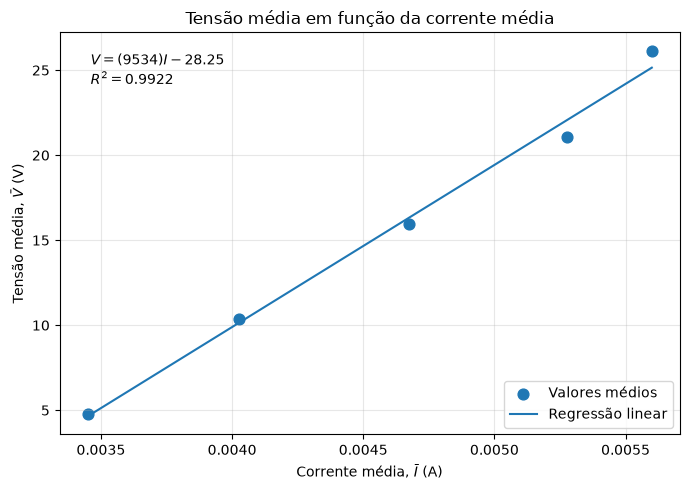

In [16]:
x_reta = np.linspace(x.min(), x.max(), 200)
y_reta = R_grafico * x_reta + intercepto

fig, ax = plt.subplots(figsize=(7, 5))

# Cinco pontos médios
ax.scatter(
    x,
    y,
    s=60,
    label="Valores médios"
)

# Reta de regressão linear
ax.plot(
    x_reta,
    y_reta,
    label="Regressão linear"
)

texto = (
    f"$V = ({R_grafico:.0f})I"
    f"{intercepto:+.2f}$\n"
    f"$R^2 = {r2:.4f}$"
)

ax.text(
    0.05,
    0.95,
    texto,
    transform=ax.transAxes,
    va="top"
)

ax.set_xlabel(r"Corrente média, $\bar{I}$ (A)")
ax.set_ylabel(r"Tensão média, $\bar{V}$ (V)")
ax.set_title("Tensão média em função da corrente média")
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

## Discussão do resultado

O fator de escala do miliamperímetro foi determinado pela razão entre
a faixa de 75 mA e a escala de 0 a 75, resultando em 1 mA por divisão.
Assim, nenhuma alteração numérica foi aplicada às leituras médias.

A regressão linear dos cinco pares de valores médios forneceu uma
resistência de aproximadamente 9,53 kΩ, muito superior ao valor de
390 Ω obtido pela medição direta.

Além disso, o intercepto da reta foi significativamente diferente de
zero. A comparação entre as correntes registradas e as correntes
esperadas para um resistor de 390 Ω mostrou que não existe um único
fator multiplicativo capaz de compatibilizar todos os pontos.

Dessa forma, a divergência não pode ser atribuída apenas à conversão
da escala do miliamperímetro. Os resultados indicam a possibilidade de
erro instrumental, ligação inadequada, defeito de calibração ou outro
problema ocorrido durante a aquisição das correntes.